Predicting London House Prices Using Machine Learning, The Role of Market Activity, CPI and Bank Rate, 1995–2020

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# adjust this file path as required depending on the local directory structure
df = pd.read_csv("Housing Project  - housing_london_with_bankrate_cpi.csv")

df.head()

,date,area,average_price,code,houses_sold,no_of_crimes,borough_flag,cpi_index_2015_100,cpi_yoy_pct,cpi_mom_pct,bank_rate_monthly_avg
0,1995-01-01,city of london,91449,E09000001,17.0,NaN,1,56.472895,3.336921,0.000000,6.130000
1,1995-02-01,city of london,82203,E09000001,7.0,NaN,1,56.816046,3.371388,0.607639,6.612143
2,1995-03-01,city of london,79121,E09000001,14.0,NaN,1,57.051350,3.504091,0.414150,6.630000
3,1995-04-01,city of london,77101,E09000001,7.0,NaN,1,57.629805,3.322201,1.013920,6.630000
4,1995-05-01,city of london,84409,E09000001,10.0,NaN,1,57.865109,3.398739,0.408302,6.630000


In [ ]:
df.shape
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13549 entries, 0 to 13548
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   13549 non-null  object 
 1   area                   13549 non-null  object 
 2   average_price          13549 non-null  int64  
 3   code                   13549 non-null  object 
 4   houses_sold            13455 non-null  float64
 5   no_of_crimes           7439 non-null   float64
 6   borough_flag           13549 non-null  int64  
 7   cpi_index_2015_100     13549 non-null  float64
 8   cpi_yoy_pct            13549 non-null  float64
 9   cpi_mom_pct            13549 non-null  float64
 10  bank_rate_monthly_avg  13549 non-null  float64
dtypes: float64(6), int64(2), object(3)
memory usage: 1.1+ MB


,average_price,houses_sold,no_of_crimes,borough_flag,cpi_index_2015_100,cpi_yoy_pct,cpi_mom_pct,bank_rate_monthly_avg
count,1.354900e+04,13455.000000,7439.000000,13549.000000,13549.000000,13549.000000,13549.000000,13549.000000
mean,2.635197e+05,3893.994129,2158.352063,0.733338,81.669197,2.826317,0.229840,3.188758
std,1.876175e+05,12114.402476,902.087742,0.442230,16.666110,1.266003,0.387009,2.509341
min,4.072200e+04,2.000000,0.000000,0.000000,56.472895,-1.566702,-1.431757,0.250000
25%,1.323800e+05,247.000000,1623.000000,0.000000,66.953715,2.210133,0.000000,0.500000
50%,2.229190e+05,371.000000,2132.000000,1.000000,80.179746,2.945826,0.277900,4.000000
75%,3.368430e+05,3146.000000,2582.000000,1.000000,97.425548,3.504091,0.467914,5.500000
max,1.463378e+06,132163.000000,7461.000000,1.000000,112.896769,5.591809,1.119168,7.500000


standardise columns

In [ ]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

df.columns

Index(['date', 'area', 'average_price', 'code', 'houses_sold', 'no_of_crimes',
       'borough_flag', 'cpi_index_2015_100', 'cpi_yoy_pct', 'cpi_mom_pct',
       'bank_rate_monthly_avg'],
      dtype='object')

In [ ]:
missing = df.isnull().sum().sort_values(ascending=False)
missing

,0
no_of_crimes,6110
houses_sold,94
date,0
average_price,0
area,0
code,0
borough_flag,0
cpi_index_2015_100,0
cpi_yoy_pct,0
cpi_mom_pct,0


In [ ]:
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_percent.sort_values(ascending=False)

,0
no_of_crimes,45.095579
houses_sold,0.693778
date,0.000000
average_price,0.000000
area,0.000000
code,0.000000
borough_flag,0.000000
cpi_index_2015_100,0.000000
cpi_yoy_pct,0.000000
cpi_mom_pct,0.000000


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df = df.drop_duplicates()
df.shape

(13549, 11)

converting all date values

In [ ]:
df['date'] = pd.to_datetime(df['date'], errors='coerce')

df['date'].head()

,date
0,1995-01-01
1,1995-02-01
2,1995-03-01
3,1995-04-01
4,1995-05-01


In [ ]:
df['date'].isnull().sum()

np.int64(0)

In [ ]:
df = df.dropna(subset=['date']) 

In [ ]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['quarter'] = df['date'].dt.quarter

In [ ]:
df[['date', 'year', 'month', 'quarter']].head()

,date,year,month,quarter
0,1995-01-01,1995,1,1
1,1995-02-01,1995,2,1
2,1995-03-01,1995,3,1
3,1995-04-01,1995,4,2
4,1995-05-01,1995,5,2


In [ ]:
df['area'].unique()

array(['city of london', 'barking and dagenham', 'barnet', 'bexley',
       'brent', 'bromley', 'camden', 'croydon', 'ealing', 'enfield',
       'tower hamlets', 'greenwich', 'hackney', 'south east',
       'hammersmith and fulham', 'haringey', 'harrow', 'havering',
       'hillingdon', 'hounslow', 'islington', 'kensington and chelsea',
       'kingston upon thames', 'lambeth', 'lewisham', 'merton', 'newham',
       'redbridge', 'richmond upon thames', 'southwark', 'sutton',
       'waltham forest', 'wandsworth', 'westminster', 'inner london',
       'outer london', 'north east', 'north west', 'yorks and the humber',
       'east midlands', 'west midlands', 'east of england', 'london',
       'south west', 'england'], dtype=object)

In [ ]:
df['area'].value_counts()

,count
area,
tower hamlets,302
hackney,302
enfield,302
south east,302
barking and dagenham,301
brent,301
bexley,301
barnet,301
bromley,301


In [ ]:
df['area'] = df['area'].str.lower().str.strip()

# Keep only London boroughs + City of London
london_areas = [
    'barking and dagenham',
    'barnet',
    'bexley',
    'brent',
    'bromley',
    'camden',
    'city of london',
    'croydon',
    'ealing',
    'enfield',
    'greenwich',
    'hackney',
    'hammersmith and fulham',
    'haringey',
    'harrow',
    'havering',
    'hillingdon',
    'hounslow',
    'islington',
    'kensington and chelsea',
    'kingston upon thames',
    'lambeth',
    'lewisham',
    'merton',
    'newham',
    'redbridge',
    'richmond upon thames',
    'southwark',
    'sutton',
    'tower hamlets',
    'waltham forest',
    'wandsworth',
    'westminster'
]


df_london = df[df['area'].isin(london_areas)].copy()

print(f"Number of London areas: {df_london['area'].nunique()}")
print(f"Dataset shape: {df_london.shape}")
print(sorted(df_london['area'].unique()))

Number of London areas: 33
Dataset shape: (9936, 14)
['barking and dagenham', 'barnet', 'bexley', 'brent', 'bromley', 'camden', 'city of london', 'croydon', 'ealing', 'enfield', 'greenwich', 'hackney', 'hammersmith and fulham', 'haringey', 'harrow', 'havering', 'hillingdon', 'hounslow', 'islington', 'kensington and chelsea', 'kingston upon thames', 'lambeth', 'lewisham', 'merton', 'newham', 'redbridge', 'richmond upon thames', 'southwark', 'sutton', 'tower hamlets', 'waltham forest', 'wandsworth', 'westminster']


In [ ]:
numeric_cols = ['average_price', 'houses_sold', 'no_of_crimes', 'cpi', 'bank_rate']

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13549 entries, 0 to 13548
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date                   13549 non-null  datetime64[ns]
 1   area                   13549 non-null  object        
 2   average_price          13549 non-null  int64         
 3   code                   13549 non-null  object        
 4   houses_sold            13455 non-null  float64       
 5   no_of_crimes           7439 non-null   float64       
 6   borough_flag           13549 non-null  int64         
 7   cpi_index_2015_100     13549 non-null  float64       
 8   cpi_yoy_pct            13549 non-null  float64       
 9   cpi_mom_pct            13549 non-null  float64       
 10  bank_rate_monthly_avg  13549 non-null  float64       
 11  year                   13549 non-null  int32         
 12  month                  13549 non-null  int32         
 13  q

In [ ]:
df[df['average_price'] <= 0]

,date,area,average_price,code,houses_sold,no_of_crimes,borough_flag,cpi_index_2015_100,cpi_yoy_pct,cpi_mom_pct,bank_rate_monthly_avg,year,month,quarter


In [ ]:
df[df['houses_sold'] < 0]

,date,area,average_price,code,houses_sold,no_of_crimes,borough_flag,cpi_index_2015_100,cpi_yoy_pct,cpi_mom_pct,bank_rate_monthly_avg,year,month,quarter


In [ ]:
df[df['no_of_crimes'] == 0].head()

,date,area,average_price,code,houses_sold,no_of_crimes,borough_flag,cpi_index_2015_100,cpi_yoy_pct,cpi_mom_pct,bank_rate_monthly_avg,year,month,quarter
72,2001-01-01,city of london,284262,E09000001,24.0,0.0,1,66.179174,2.708460,-0.633005,6.000000,2001,1,1
73,2001-02-01,city of london,198137,E09000001,37.0,0.0,1,66.522325,2.678571,0.518519,5.812500,2001,2,1
74,2001-03-01,city of london,189033,E09000001,44.0,0.0,1,66.600760,2.258016,0.117907,5.750000,2001,3,1
75,2001-04-01,city of london,205494,E09000001,38.0,0.0,1,66.953715,1.773472,0.529957,5.533333,2001,4,2
76,2001-05-01,city of london,223459,E09000001,30.0,0.0,1,67.375301,2.049302,0.629668,5.322581,2001,5,2


In [ ]:
print(df.columns.tolist())

['date', 'area', 'average_price', 'code', 'houses_sold', 'no_of_crimes', 'borough_flag', 'cpi_index_2015_100', 'cpi_yoy_pct', 'cpi_mom_pct', 'bank_rate_monthly_avg', 'year', 'month', 'quarter']


In [ ]:
important_cols = [
    'date',
    'area',
    'average_price',
    'houses_sold',
    'no_of_crimes',
    'cpi_index_2015_100',
    'bank_rate_monthly_avg'
]

df_clean = df.dropna(subset=important_cols)

print(df_clean.shape)
print(df_clean.isnull().sum())

(7375, 14)
date                     0
area                     0
average_price            0
code                     0
houses_sold              0
no_of_crimes             0
borough_flag             0
cpi_index_2015_100       0
cpi_yoy_pct              0
cpi_mom_pct              0
bank_rate_monthly_avg    0
year                     0
month                    0
quarter                  0
dtype: int64


In [ ]:
df_clean = df_clean.sort_values(by=['area', 'date'])

df_clean.head()

,date,area,average_price,code,houses_sold,no_of_crimes,borough_flag,cpi_index_2015_100,cpi_yoy_pct,cpi_mom_pct,bank_rate_monthly_avg,year,month,quarter
373,2001-01-01,barking and dagenham,82343,E09000002,215.0,1771.0,1,66.179174,2.708460,-0.633005,6.000000,2001,1,1
374,2001-02-01,barking and dagenham,83266,E09000002,238.0,1600.0,1,66.522325,2.678571,0.518519,5.812500,2001,2,1
375,2001-03-01,barking and dagenham,84058,E09000002,274.0,1759.0,1,66.600760,2.258016,0.117907,5.750000,2001,3,1
376,2001-04-01,barking and dagenham,83965,E09000002,241.0,1643.0,1,66.953715,1.773472,0.529957,5.533333,2001,4,2
377,2001-05-01,barking and dagenham,85124,E09000002,283.0,1809.0,1,67.375301,2.049302,0.629668,5.322581,2001,5,2


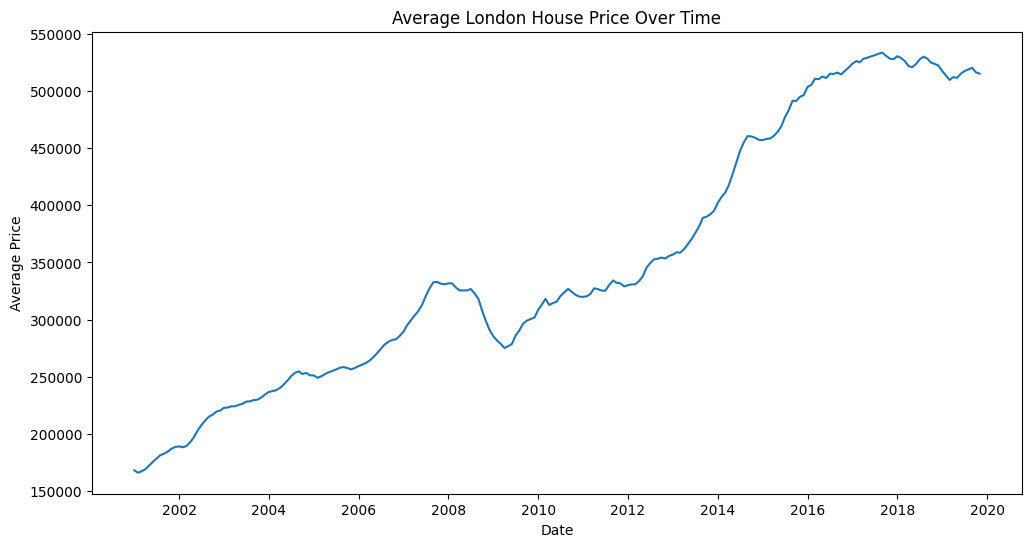

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(df_clean.groupby('date')['average_price'].mean())
plt.title('Average London House Price Over Time')
plt.xlabel('Date')
plt.ylabel('Average Price')
plt.show()

In [ ]:
df_clean.info()
df_clean.head()
df_clean.tail()

<class 'pandas.core.frame.DataFrame'>
Index: 7375 entries, 373 to 9935
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date                   7375 non-null   datetime64[ns]
 1   area                   7375 non-null   object        
 2   average_price          7375 non-null   int64         
 3   code                   7375 non-null   object        
 4   houses_sold            7375 non-null   float64       
 5   no_of_crimes           7375 non-null   float64       
 6   borough_flag           7375 non-null   int64         
 7   cpi_index_2015_100     7375 non-null   float64       
 8   cpi_yoy_pct            7375 non-null   float64       
 9   cpi_mom_pct            7375 non-null   float64       
 10  bank_rate_monthly_avg  7375 non-null   float64       
 11  year                   7375 non-null   int32         
 12  month                  7375 non-null   int32         
 13  quarte

,date,area,average_price,code,houses_sold,no_of_crimes,borough_flag,cpi_index_2015_100,cpi_yoy_pct,cpi_mom_pct,bank_rate_monthly_avg,year,month,quarter
9931,2019-07-01,westminster,957897,E09000033,168.0,6991.0,1,111.975162,2.771529,-0.035011,0.75,2019,7,3
9932,2019-08-01,westminster,914870,E09000033,156.0,7069.0,1,112.828138,2.640029,0.761755,0.75,2019,8,3
9933,2019-09-01,westminster,925955,E09000033,169.0,6384.0,1,112.553617,2.426838,-0.243309,0.75,2019,9,3
9934,2019-10-01,westminster,927864,E09000033,168.0,7208.0,1,112.318314,2.066999,-0.209059,0.75,2019,10,4
9935,2019-11-01,westminster,955615,E09000033,150.0,6843.0,1,112.553617,2.253496,0.209497,0.75,2019,11,4


In [ ]:
df_clean.isnull().sum()

,0
date,0
area,0
average_price,0
code,0
houses_sold,0
no_of_crimes,0
borough_flag,0
cpi_index_2015_100,0
cpi_yoy_pct,0
cpi_mom_pct,0


In [ ]:
data_dictionary = pd.DataFrame({
    'Column': df_clean.columns,
    'Data Type': df_clean.dtypes.astype(str),
    'Description': [
        'Monthly date',
        'London area or borough',
        'Average house price (£)',
        'ONS area code',
        'Number of houses sold',
        'Recorded crimes',
        'Indicator for London borough',
        'Consumer Price Index (2015=100)',
        'Year-on-year CPI percentage change',
        'Month-on-month CPI percentage change',
        'Bank of England average monthly interest rate',
        'Year extracted from date',
        'Month extracted from date',
        'Quarter extracted from date'
    ]
})

data_dictionary

,Column,Data Type,Description
date,date,datetime64[ns],Monthly date
area,area,object,London area or borough
average_price,average_price,int64,Average house price (£)
code,code,object,ONS area code
houses_sold,houses_sold,float64,Number of houses sold
no_of_crimes,no_of_crimes,float64,Recorded crimes
borough_flag,borough_flag,int64,Indicator for London borough
cpi_index_2015_100,cpi_index_2015_100,float64,Consumer Price Index (2015=100)
cpi_yoy_pct,cpi_yoy_pct,float64,Year-on-year CPI percentage change
cpi_mom_pct,cpi_mom_pct,float64,Month-on-month CPI percentage change


In [ ]:
print(len(df_clean.columns))
print(len(df_clean.dtypes))

14
14


In [ ]:
df_clean.to_csv("clean_london_house_prices.csv", index=False)

# Google Colab only downloads the generated file to the local computer.
# when running the notebook outside Google Colab, this can be skipped
from google.colab import files
files.download("clean_london_house_prices.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
data_dictionary.to_csv("data_dictionary.csv", index=False)
files.download("data_dictionary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>